# CNN simples no MNIST

Código de apoio do seminário de Redes Neurais Convolucionais (CPE727, PEE/COPPE/UFRJ).
Eraldo Silva Junior, 2026.

Primeiro fazemos uma convolução na mão, depois treinamos uma CNN pequena para reconhecer dígitos e olhamos o que ela aprendeu.

Para rodar: `pip install torch torchvision matplotlib numpy`. As funções de carregar os dados, treinar e calcular a acurácia estão em `libs.py`, nesta mesma pasta.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from libs import escolher_device, carregar_mnist, treinar, acuracia

torch.manual_seed(0)
device = escolher_device()
print(device)

cpu


## 1. Convolução na mão

A ideia é a mesma dos slides: o kernel 3×3 passa por cima da imagem e, em cada posição, multiplicamos ele pelos pixels que estão embaixo e somamos tudo. Esse número é um pixel da saída.

Imagem de teste: um quadrado branco (1) num fundo preto (0). O kernel é o filtro de Sobel, que detecta bordas verticais. Ele tem -1, -2, -1 na coluna da esquerda e +1, +2, +1 na da direita, então a resposta é grande quando a imagem muda de escuro para claro da esquerda para a direita.

In [2]:
def conv2d_na_mao(img, k):
    H, W = img.shape
    kh, kw = k.shape
    saida = np.zeros((H - kh + 1, W - kw + 1))
    for i in range(saida.shape[0]):
        for j in range(saida.shape[1]):
            janela = img[i:i + kh, j:j + kw]
            saida[i, j] = np.sum(janela * k)
    return saida

img = np.zeros((12, 12))
img[3:9, 3:9] = 1

sobel = np.array([[-1, 0, 1],
                  [-2, 0, 2],
                  [-1, 0, 1]], dtype=float)

saida = conv2d_na_mao(img, sobel)
print(saida.astype(int))

[[ 0  0  0  0  0  0  0  0  0  0]
 [ 0  1  1  0  0  0  0 -1 -1  0]
 [ 0  3  3  0  0  0  0 -3 -3  0]
 [ 0  4  4  0  0  0  0 -4 -4  0]
 [ 0  4  4  0  0  0  0 -4 -4  0]
 [ 0  4  4  0  0  0  0 -4 -4  0]
 [ 0  4  4  0  0  0  0 -4 -4  0]
 [ 0  3  3  0  0  0  0 -3 -3  0]
 [ 0  1  1  0  0  0  0 -1 -1  0]
 [ 0  0  0  0  0  0  0  0  0  0]]


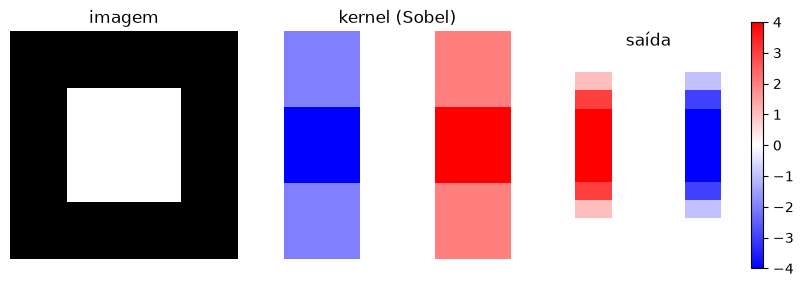

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
ax[0].imshow(img, cmap="gray"); ax[0].set_title("imagem")
ax[1].imshow(sobel, cmap="bwr", vmin=-2, vmax=2); ax[1].set_title("kernel (Sobel)")
im = ax[2].imshow(saida, cmap="bwr", vmin=-4, vmax=4); ax[2].set_title("saída")
fig.colorbar(im, ax=ax[2])
for a in ax: a.axis("off")

Na saída, a borda esquerda do quadrado aparece em vermelho (+4, o fundo preto vira branco) e a borda direita em azul (-4, o branco vira preto). Dentro do quadrado e no fundo a saída é zero, porque ali a imagem não muda.

Agora o mesmo cálculo com a camada `nn.Conv2d` do PyTorch, colocando o Sobel como peso. O resultado tem que ser igual.

Obs.: o PyTorch não espelha o kernel, ou seja, ele calcula a correlação cruzada e não a convolução da definição matemática (Goodfellow et al., seção 9.1). Numa CNN isso não muda nada, porque o kernel é aprendido.

In [4]:
camada = nn.Conv2d(1, 1, kernel_size=3, bias=False)
with torch.no_grad():
    camada.weight[:] = torch.tensor(sobel).view(1, 1, 3, 3)

x = torch.tensor(img, dtype=torch.float32).view(1, 1, 12, 12)  # (batch, canais, altura, largura)
saida_torch = camada(x)[0, 0].detach().numpy()
print("igual à versão na mão:", np.allclose(saida, saida_torch))

igual à versão na mão: True


## 2. Dados

MNIST: imagens 28×28 de dígitos escritos à mão, 60 mil para treino e 10 mil para teste. Na primeira vez ele é baixado na pasta `dados/`.

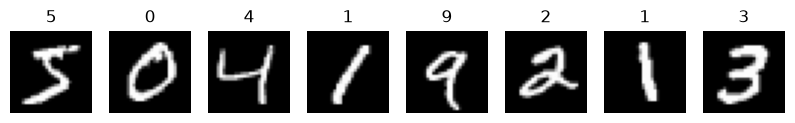

In [5]:
treino, teste, dl_treino, dl_teste = carregar_mnist()

fig, ax = plt.subplots(1, 8, figsize=(10, 1.6))
for i, a in enumerate(ax):
    x, y = treino[i]
    a.imshow(x[0], cmap="gray"); a.set_title(y); a.axis("off")

## 3. A rede

Duas camadas de convolução, cada uma seguida de ReLU e max pooling 2×2, e no fim uma camada linear que dá a nota de cada dígito (0 a 9). É parecida com a LeNet.

In [6]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=5, padding=2)   # 8 kernels 5x5
        self.conv2 = nn.Conv2d(8, 16, kernel_size=5)             # 16 kernels 5x5x8
        self.fc = nn.Linear(16 * 5 * 5, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        return self.fc(x.flatten(1))

modelo = CNN().to(device)

# tamanho do tensor depois de cada etapa, para uma imagem
x = torch.zeros(1, 1, 28, 28)
m = CNN()
print("entrada      ", tuple(x.shape[1:]))
x = m.conv1(x);           print("conv1        ", tuple(x.shape[1:]))
x = F.max_pool2d(x, 2);   print("pooling      ", tuple(x.shape[1:]))
x = m.conv2(x);           print("conv2        ", tuple(x.shape[1:]))
x = F.max_pool2d(x, 2);   print("pooling      ", tuple(x.shape[1:]))
print("linear        (10,)")

entrada       (1, 28, 28)
conv1         (8, 28, 28)
pooling       (8, 14, 14)
conv2         (16, 10, 10)
pooling       (16, 5, 5)
linear        (10,)


Quantos parâmetros a rede tem? Vale comparar a `conv1` com uma camada densa que gerasse a mesma quantidade de saídas (8 × 28 × 28 = 6272). Na densa, cada saída tem um peso para cada um dos 784 pixels. Na convolução, cada saída só olha 25 pixels (5×5) e os 8 kernels são reaproveitados em todas as posições da imagem.

In [7]:
total = sum(p.numel() for p in modelo.parameters())
conv1 = sum(p.numel() for p in modelo.conv1.parameters())
densa = 784 * 6272 + 6272

print(f"rede inteira: {total} parâmetros")
print(f"conv1:        {conv1} parâmetros (8 kernels de 5x5 + 8 bias)")
print(f"densa equivalente à conv1: {densa} parâmetros")

rede inteira: 7434 parâmetros
conv1:        208 parâmetros (8 kernels de 5x5 + 8 bias)
densa equivalente à conv1: 4923520 parâmetros


## 4. Treino

3 épocas com Adam e entropia cruzada (função `treinar` em `libs.py`).

In [8]:
treinar(modelo, dl_treino, dl_teste, device, epocas=3)

época 1: acurácia no teste = 97.39%


época 2: acurácia no teste = 98.13%


época 3: acurácia no teste = 98.35%


## 5. O que a rede aprendeu

Os 8 kernels da `conv1` depois do treino. Vermelho é peso positivo e azul é negativo. Vários lembram o Sobel da seção 1: um lado positivo, o outro negativo, em direções diferentes.

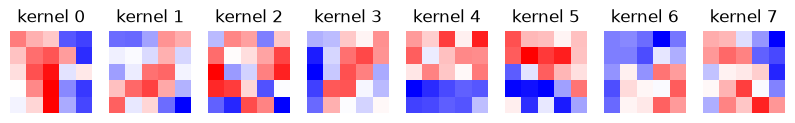

In [9]:
k = modelo.conv1.weight.detach().cpu()[:, 0]
fig, ax = plt.subplots(1, 8, figsize=(10, 1.6))
for i, a in enumerate(ax):
    lim = k[i].abs().max()
    a.imshow(k[i], cmap="bwr", vmin=-lim, vmax=lim)
    a.set_title(f"kernel {i}"); a.axis("off")

Agora passamos um dígito pela `conv1` e mostramos as 8 saídas (os mapas de características). Cada mapa é a imagem filtrada por um kernel. As partes claras são os lugares onde o kernel encontrou o padrão dele, por exemplo o traço horizontal do 7 num mapa e o traço diagonal em outro.

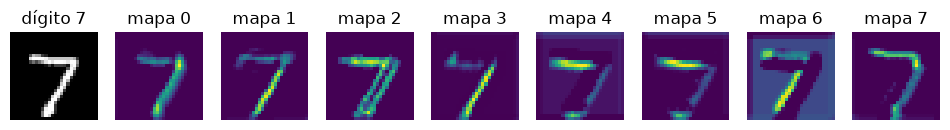

In [10]:
x, y = teste[0]
modelo.eval()
with torch.no_grad():
    mapas = F.relu(modelo.conv1(x[None].to(device)))[0].cpu()

fig, ax = plt.subplots(1, 9, figsize=(12, 1.6))
ax[0].imshow(x[0], cmap="gray"); ax[0].set_title(f"dígito {y}")
for i in range(8):
    ax[i + 1].imshow(mapas[i]); ax[i + 1].set_title(f"mapa {i}")
for a in ax: a.axis("off")

## 6. Movendo a imagem

Se a imagem anda alguns pixels para a direita, o mapa de características anda junto, porque o mesmo kernel é aplicado em todas as posições. Abaixo, o mesmo 7 na posição original e deslocado 5 pixels, com o mapa 0 de cada um.

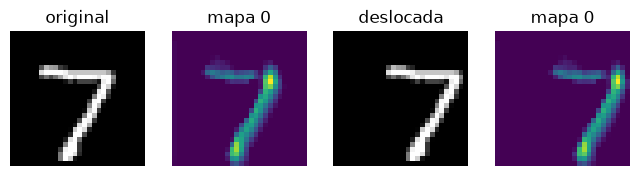

In [11]:
x_mov = torch.roll(x, shifts=5, dims=2)   # 5 pixels para a direita

with torch.no_grad():
    mapa = F.relu(modelo.conv1(x[None].to(device)))[0, 0].cpu()
    mapa_mov = F.relu(modelo.conv1(x_mov[None].to(device)))[0, 0].cpu()

fig, ax = plt.subplots(1, 4, figsize=(8, 2.2))
ax[0].imshow(x[0], cmap="gray"); ax[0].set_title("original")
ax[1].imshow(mapa); ax[1].set_title("mapa 0")
ax[2].imshow(x_mov[0], cmap="gray"); ax[2].set_title("deslocada")
ax[3].imshow(mapa_mov); ax[3].set_title("mapa 0")
for a in ax: a.axis("off")

O mapa é o mesmo, só que deslocado. Mas a resposta da rede pode mudar, porque a camada linear do final espera os traços em certas posições e os dígitos do MNIST vêm centralizados. O pooling ajuda um pouco: ele pega o máximo de cada bloco 2×2, então mexer 1 pixel quase não muda a saída dele.

Para medir, deslocamos todas as imagens de teste e calculamos a acurácia de novo:

In [12]:
for n in [0, 1, 2, 3, 4, 6]:
    print(f"{n} pixels: {acuracia(modelo, dl_teste, device, deslocamento=n):.2%}")

0 pixels: 98.35%


1 pixels: 97.65%


2 pixels: 95.70%


3 pixels: 89.55%


4 pixels: 74.65%


6 pixels: 38.81%


Com 1 ou 2 pixels a acurácia quase não cai. A partir de 3 ou 4 ela cai bastante, porque a rede nunca viu dígitos fora do centro. Uma forma comum de resolver é treinar com imagens deslocadas aleatoriamente (data augmentation).